# EDA and Data Preprocessing

In [ ]:
from pathlib import Path

data_dir = Path("/content/drive/MyDrive/Dataset/temp_labels")

if data_dir.exists():
    # Count only the directories inside temp_labels
    folders = [f for f in data_dir.iterdir() if f.is_dir()]

    print(f"Total folders found: {len(folders)}")
else:
    print("Path does not exist.")

Total folders found: 496


## Count image per class

In [ ]:
from pathlib import Path

data_dir = Path("/content/drive/MyDrive/Dataset/temp_labels")

if data_dir.exists():
    # Get all sub-directories
    folders = sorted([f for f in data_dir.iterdir() if f.is_dir()])

    print(f"{'Folder Name (Upazila/District)':<60} | {'File Count':<10}")
    print("-" * 75)

    total_images = 0

    for folder in folders:
        # Count only files inside this specific folder
        file_count = len([f for f in folder.iterdir() if f.is_file()])

        print(f"{folder.name:<60} | {file_count:<10}")
        total_images += file_count

    print("-" * 75)
    print(f"Total Folders: {len(folders)}")
    print(f"Total Images across all folders: {total_images}")

else:
    print("Path does not exist. Please check the directory name.")

Folder Name (Upazila/District)                               | File Count
---------------------------------------------------------------------------
Abhaynagar Upazila,Jashore                                   | 15        
Adamdighi Upazila,Bogura                                     | 20        
Aditmari Upazila,Lalmonirhat                                 | 19        
Agailjhara Upazila,Barishal                                  | 18        
Ajmiriganj Upazila,Habiganj                                  | 18        
Akhaura Upazila,Brahmanbaria                                 | 29        
Akkelpur Upazila,Joypurhat                                   | 20        
Alamdanga Upazila,Chuadanga                                  | 15        
Alfadanga Upazila,Faridpur                                   | 17        
Ali Kadam Upazila,Bandarban                                  | 27        
Amtali Upazila,Barguna                                       | 14        
Anwara Upazila,Chattogram           

In [ ]:
import os, re
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image_dataset_from_directory

print("TF:", tf.__version__)

# CONFIG

IMG_SIZE = (128, 128)
BATCH = 32
SEED = 1337

print("data_dir exists:", data_dir.exists(), data_dir)


TF: 2.19.0
data_dir exists: True /content/drive/MyDrive/Dataset/temp_labels


## Preview image path

In [ ]:
from pathlib import Path
import pandas as pd

rows = []
data_dir = Path("/content/drive/MyDrive/Dataset/temp_labels")

for folder in sorted(data_dir.iterdir()):
    if not folder.is_dir():
        continue

    pair_label = folder.name  # e.g., "Bagerhat_Chitalmari"

    # Extract only Upazila name (after "_")
    if "_" in pair_label:
        upazila_name = pair_label.split("_", 1)[1]
    else:
        upazila_name = pair_label  # fallback safety

    imgs = [p for p in folder.iterdir() if p.suffix.lower() in [".png", ".jpg", ".jpeg"]]

    rows.append({
        "upazila": upazila_name,
        "n_images": len(imgs),
        "path": str(folder)
    })

df = pd.DataFrame(rows)

print("Total upazila folders:", len(df))
print("Total images:", df["n_images"].sum())

df.head(10)


Total upazila folders: 496
Total images: 9808


,upazila,n_images,path
0,"Abhaynagar Upazila,Jashore",15,/content/drive/MyDrive/Dataset/temp_labels/Abh...
1,"Adamdighi Upazila,Bogura",20,/content/drive/MyDrive/Dataset/temp_labels/Ada...
2,"Aditmari Upazila,Lalmonirhat",18,/content/drive/MyDrive/Dataset/temp_labels/Adi...
3,"Agailjhara Upazila,Barishal",18,/content/drive/MyDrive/Dataset/temp_labels/Aga...
4,"Ajmiriganj Upazila,Habiganj",18,/content/drive/MyDrive/Dataset/temp_labels/Ajm...
5,"Akhaura Upazila,Brahmanbaria",29,/content/drive/MyDrive/Dataset/temp_labels/Akh...
6,"Akkelpur Upazila,Joypurhat",20,/content/drive/MyDrive/Dataset/temp_labels/Akk...
7,"Alamdanga Upazila,Chuadanga",15,/content/drive/MyDrive/Dataset/temp_labels/Ala...
8,"Alfadanga Upazila,Faridpur",17,/content/drive/MyDrive/Dataset/temp_labels/Alf...
9,"Ali Kadam Upazila,Bandarban",27,/content/drive/MyDrive/Dataset/temp_labels/Ali...


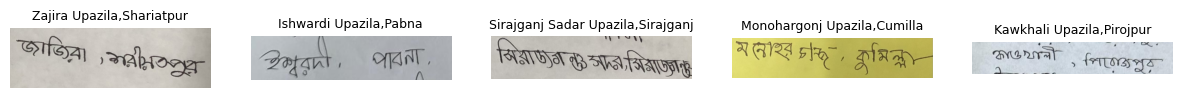

In [ ]:
# plot random class image:
import random
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path


NUM_CLASSES = 5

if data_dir.exists():
    # get all class folders
    folders = [f for f in data_dir.iterdir() if f.is_dir()]

    # randomly select classes
    selected_folders = random.sample(folders, min(NUM_CLASSES, len(folders)))

    fig, axes = plt.subplots(1, len(selected_folders), figsize=(15, 4))

    if len(selected_folders) == 1:
        axes = [axes]

    for ax, folder in zip(axes, selected_folders):
        images = [f for f in folder.iterdir() if f.is_file()]

        if len(images) == 0:
            ax.axis("off")
            continue

        # pick one random image from this class
        img_path = random.choice(images)
        img = Image.open(img_path)

        ax.imshow(img)
        ax.set_title(folder.name, fontsize=9)
        ax.axis("off")

    plt.show()

else:
    print("Path does not exist. Please check the directory name.")

## 1.Resize and normalize

In [ ]:
from pathlib import Path
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

class UpazilaDistrictDataset(Dataset):
    def __init__(self, data_dir, transform=None):
        self.data_dir = Path(data_dir)
        self.samples = []          # list of (img_path, label_index)
        self.class_names = sorted([d.name for d in self.data_dir.iterdir() if d.is_dir()])
        self.class_to_idx = {name: i for i, name in enumerate(self.class_names)}

        for folder in sorted(self.data_dir.iterdir()):
            if not folder.is_dir():
                continue
            label = self.class_to_idx[folder.name]
            for img_file in folder.iterdir():
                if img_file.suffix.lower() in ['.png', '.jpg', '.jpeg']:
                    self.samples.append((img_file, label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

# Define the preprocessing pipeline (resize + normalize)
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),                        # converts to [0,1] float tensor
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

In [ ]:
import torch
from pathlib import Path
from PIL import Image
from torchvision import transforms
from tqdm import tqdm

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

data_dir = Path("/content/drive/MyDrive/Dataset/temp_labels")
output_dir = Path("/content/drive/MyDrive/Dataset/preprocessed")
output_dir.mkdir(exist_ok=True)

error_log = []

for folder in tqdm(sorted(data_dir.iterdir()), desc="Folders"):
    if not folder.is_dir():
        continue
    class_name = folder.name
    out_class_dir = output_dir / class_name
    out_class_dir.mkdir(exist_ok=True)

    for img_file in folder.iterdir():
        if img_file.suffix.lower() not in ['.png', '.jpg', '.jpeg']:
            continue
        try:
            img = Image.open(img_file).convert('RGB')
            tensor = transform(img)
            save_path = out_class_dir / f"{img_file.stem}.pt"
            torch.save(tensor, save_path)
        except Exception as e:
            error_log.append((str(img_file), str(e)))

print("Errors:", error_log[:10])
print("Done.")

Done.


## 2. Train test Validation split

In [ ]:
from pathlib import Path
from collections import defaultdict
import shutil, hashlib, random
import pandas as pd

# ✅ Your actual dataset root
RAW_ROOT = Path("/content/drive/MyDrive/Dataset/temp_labels")

# ✅ Output dataset
OUT_ROOT = Path("/content/drive/MyDrive/Thesis_project/datasets")
TRAIN_DIR = OUT_ROOT / "train"
VAL_DIR   = OUT_ROOT / "val"
TEST_DIR  = OUT_ROOT / "test"

IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}
BASE_SEED = 123
MIN_IMAGES_PER_CLASS = 5

def reset_dir(p: Path):
    if p.exists():
        shutil.rmtree(p)
    p.mkdir(parents=True, exist_ok=True)

def stable_seed_from_string(s: str, base_seed: int = 123) -> int:
    h = hashlib.md5((s + str(base_seed)).encode("utf-8")).hexdigest()
    return int(h[:8], 16)

def list_images(folder: Path):
    return sorted([p for p in folder.iterdir()
                   if p.is_file() and p.suffix.lower() in IMG_EXTS])

def safe_copy(src: Path, dst: Path):
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(str(src), str(dst))

assert RAW_ROOT.exists(), f"RAW_ROOT not found: {RAW_ROOT}"

# ===============================
# 1 Build mapping: pair_label -> image paths
# ===============================
label_to_files = defaultdict(list)

class_dirs = sorted([p for p in RAW_ROOT.iterdir() if p.is_dir()])
print(f"✅ Found {len(class_dirs)} pair folders.\n")

for class_dir in class_dirs:
    pair_label = class_dir.name
    imgs = list_images(class_dir)
    if len(imgs) == 0:
        continue
    label_to_files[pair_label].extend(imgs)

total_classes_before = len(label_to_files)
total_images_before = sum(len(v) for v in label_to_files.values())

print("📌 Total classes (before skip):", total_classes_before)
print("📌 Total images  (before skip):", total_images_before)

# ===============================
# 2 Skip small classes
# ===============================
kept = {k: v for k, v in label_to_files.items() if len(v) >= MIN_IMAGES_PER_CLASS}
skipped = {k: v for k, v in label_to_files.items() if len(v) < MIN_IMAGES_PER_CLASS}

print("\n🧹 Skipping small classes ...")
print(f"✅ Keeping classes >= {MIN_IMAGES_PER_CLASS} images:", len(kept))
print(f"❌ Skipping classes <", MIN_IMAGES_PER_CLASS, ":", len(skipped))

# Save skipped list
skipped_csv = "/content/drive/MyDrive/Thesis_project/skipped_classes_under_5.csv"
pd.DataFrame([(k, len(v)) for k, v in skipped.items()],
             columns=["pair_label", "n_images"]
             ).sort_values("n_images").to_csv(skipped_csv, index=False)

print("💾 Skipped list saved to:", skipped_csv)

label_to_files = kept

# ===============================
# 3 Split (80/20/10)
# ===============================
train_ratio, val_ratio, test_ratio = 0.7, 0.2, 0.1

def split_one_class(files, label):
    rng = random.Random(stable_seed_from_string(label, BASE_SEED))
    files = files[:]
    rng.shuffle(files)
    n = len(files)

    n_val  = max(1, int(round(n * val_ratio)))
    n_test = max(1, int(round(n * test_ratio)))
    n_train = n - n_val - n_test

    if n_train < 1:
        n_train = 1
        n_val = max(1, n_val - 1)

    return files[:n_train], files[n_train:n_train+n_val], files[n_train+n_val:]

# ===============================
# 4 Reset output directories
# ===============================
reset_dir(OUT_ROOT)
TRAIN_DIR.mkdir(parents=True, exist_ok=True)
VAL_DIR.mkdir(parents=True, exist_ok=True)
TEST_DIR.mkdir(parents=True, exist_ok=True)

# ===============================
# 5 Copy into train/val/test
# ===============================
split_counts = {"train": 0, "val": 0, "test": 0}

print("\n🚚 Copying dataset...")

for idx, (label, files) in enumerate(sorted(label_to_files.items()), start=1):
    tr, va, te = split_one_class(files, label)

    for f in tr:
        safe_copy(f, TRAIN_DIR / label / f.name)
    for f in va:
        safe_copy(f, VAL_DIR / label / f.name)
    for f in te:
        safe_copy(f, TEST_DIR / label / f.name)

    split_counts["train"] += len(tr)
    split_counts["val"]   += len(va)
    split_counts["test"]  += len(te)

    if idx % 50 == 0:
        print(f"  ...processed {idx}/{len(label_to_files)} classes")

print("\n✅ Split complete!")
print("📦 Train images:", split_counts["train"])
print("📦 Val images  :", split_counts["val"])
print("📦 Test images :", split_counts["test"])
print("\n📁 Dataset ready at:", OUT_ROOT)


✅ Found 496 pair folders.

📌 Total classes (before skip): 496
📌 Total images  (before skip): 9808

🧹 Skipping small classes ...
✅ Keeping classes >= 5 images: 496
❌ Skipping classes < 5 : 0
💾 Skipped list saved to: /content/drive/MyDrive/Thesis_project/skipped_classes_under_5.csv

🚚 Copying dataset...
  ...processed 50/496 classes
  ...processed 100/496 classes
  ...processed 150/496 classes
  ...processed 200/496 classes
  ...processed 250/496 classes
  ...processed 300/496 classes
  ...processed 350/496 classes
  ...processed 400/496 classes
  ...processed 450/496 classes

✅ Split complete!
📦 Train images: 6812
📦 Val images  : 1949
📦 Test images : 1047

📁 Dataset ready at: /content/drive/MyDrive/Thesis_project/datasets


## 3. Data Augmentation

In [ ]:
# =========================
# Imports +  Paths + Quick counts
# =========================


import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms


# ---- paths ----

train_dir = "/content/drive/MyDrive/Thesis_project/datasets/train"
val_dir   = "/content/drive/MyDrive/Thesis_project/datasets/val"
test_dir  = "/content/drive/MyDrive/Thesis_project/datasets/test"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("✅ device:", device)

# build class map from TRAIN ONLY (important)
train_base = datasets.ImageFolder(root=train_dir)
classes = train_base.classes
class_to_idx = train_base.class_to_idx
num_classes = len(classes)

print(f"✅ Found {num_classes} classes.")
print("✅ Example class:", classes[0])


✅ device: cuda
✅ Found 496 classes.
✅ Example class: Abhaynagar Upazila,Jashore


In [ ]:
# =========================
# CHECK AUGMENTATION NEEDS
# =========================

from pathlib import Path
import numpy as np

train_dir = Path(train_dir)
assert train_dir.exists(), f"TRAIN_DIR not found: {train_dir}"

IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}

def list_images(folder: Path):
    return sorted([
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMG_EXTS
    ])

# ==============================
# COUNT PER CLASS
# ==============================
class_dirs = sorted([p for p in train_dir.iterdir() if p.is_dir()])
train_counts = {cd.name: len(list_images(cd)) for cd in class_dirs}

TARGET = int(max(train_counts.values()) * 1.5) if train_counts else 0

print(f"\n📌 Classes in TRAIN: {len(train_counts)}")
print(f"📌 TARGET per class: {TARGET}\n")

# ==============================
# CALCULATE NEEDS
# ==============================
needs = {}
total_need = 0

for label, count in train_counts.items():
    need = max(0, TARGET - count)
    if need > 0:
        needs[label] = (count, need)
        total_need += need

print(f"🧮 Total images needed for augmentation: {total_need}\n")

# ==============================
# SHOW SAMPLE CLASSES
# ==============================
print("🔍 Sample classes needing augmentation:\n")

sample_items = list(needs.items())[:10]  # show first 10 classes

for label, (cur, need) in sample_items:
    print(f"Class: {label}")
    print(f"   current images : {cur}")
    print(f"   need augment   : {need}")
    print("")

# ==============================
# SUMMARY TABLE
# ==============================
import pandas as pd

df = pd.DataFrame([
    [label, count, max(0, TARGET-count)]
    for label, count in train_counts.items()
], columns=["class", "current", "need"])

print("\n📊 Smallest classes:")
print(df.sort_values("current").head(10).to_string(index=False))

print("\n📊 Largest classes:")
print(df.sort_values("current", ascending=False).head(10).to_string(index=False))



📌 Classes in TRAIN: 496
📌 TARGET per class: 36

🧮 Total images needed for augmentation: 11044

🔍 Sample classes needing augmentation:

Class: Abhaynagar Upazila,Jashore
   current images : 10
   need augment   : 26

Class: Adamdighi Upazila,Bogura
   current images : 14
   need augment   : 22

Class: Aditmari Upazila,Lalmonirhat
   current images : 12
   need augment   : 24

Class: Agailjhara Upazila,Barishal
   current images : 12
   need augment   : 24

Class: Ajmiriganj Upazila,Habiganj
   current images : 12
   need augment   : 24

Class: Akhaura Upazila,Brahmanbaria
   current images : 20
   need augment   : 16

Class: Akkelpur Upazila,Joypurhat
   current images : 14
   need augment   : 22

Class: Alamdanga Upazila,Chuadanga
   current images : 10
   need augment   : 26

Class: Alfadanga Upazila,Faridpur
   current images : 12
   need augment   : 24

Class: Ali Kadam Upazila,Bandarban
   current images : 19
   need augment   : 17


📊 Smallest classes:
                         cl

# Handwriting-safe Augmentations + Dataset with Path

In [ ]:

# Uses full augmentation style:
# Affine / Perspective / Elastic / BCG / Noise / Blur / Stroke / InkDropout / InkBleed / UnevenLight / JPEG / Stain / TextAug
# Uses dHash to avoid duplicates

import cv2
import numpy as np
from pathlib import Path
import pandas as pd
import random

# ==============================
# CONFIG
# ==============================
train_dir = Path(train_dir)
assert train_dir.exists(), f"TRAIN_DIR not found: {train_dir}"

IMG_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}

MIN_OPS, MAX_OPS = 3, 6
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

MAX_TRIES_MULT = 60   # limit tries to avoid infinite loops
SAVE_LOG_CSV = "/content/drive/MyDrive/Thesis_project/augmentation_log_step3.csv"
SAVE_COUNTS_CSV = "/content/drive/MyDrive/Thesis_project/train_counts_after_aug.csv"

# ==============================
# HELPERS
# ==============================
def list_images(folder: Path):
    return sorted([p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXTS])

def clip01(x):
    return np.clip(x, 0, 1)

def dhash_u8(gray_u8, hash_size=8):
    small = cv2.resize(gray_u8, (hash_size + 1, hash_size), interpolation=cv2.INTER_AREA)
    diff = small[:, 1:] > small[:, :-1]
    hval = 0
    for bit in diff.flatten():
        hval = (hval << 1) | int(bit)
    return hval

def read_gray01(path: Path):
    im = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if im is None:
        return None
    return im.astype(np.float32) / 255.0

# ==============================
# AUGMENTATION OPERATIONS
# ==============================
def build_ops(h, w):
    # --- helpers ---
    def add_text_dots_background_only(image, num_dots, radius=1):
        out = image.copy()
        bg_mask = (out > 0.6)
        ys, xs = np.where(bg_mask)
        if len(xs) == 0: return out
        for _ in range(int(num_dots)):
            idx = np.random.randint(0, len(xs))
            x0, y0 = int(xs[idx]), int(ys[idx])
            color = float(np.random.uniform(0.0, 0.25))
            cv2.circle(out, (x0, y0), int(radius), color, -1)
        return out

    def add_curved_stain_background_only(image, axes, intensity):
        out = image.copy()
        overlay = np.zeros_like(out, dtype=np.float32)
        cx, cy = w//2, h//2
        cv2.ellipse(overlay, (cx, cy), axes, 0, 0, 120, 1.0, 3)
        bg_weight = (out > 0.6).astype(np.float32)
        out = clip01(out - overlay * bg_weight * float(intensity))
        return out

    def elastic_distortion(image, alpha, sigma):
        rs = np.random.RandomState(None)
        dx = cv2.GaussianBlur((rs.rand(*image.shape).astype(np.float32) * 2 - 1), (0,0), sigma) * alpha
        dy = cv2.GaussianBlur((rs.rand(*image.shape).astype(np.float32) * 2 - 1), (0,0), sigma) * alpha
        xg, yg = np.meshgrid(np.arange(w), np.arange(h))
        map_x = (xg + dx).astype(np.float32)
        map_y = (yg + dy).astype(np.float32)
        return cv2.remap(image, map_x, map_y, interpolation=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)

    # --- operations ---
    def op_affine(x):
        angle = np.random.uniform(-10, 10)
        scale = np.random.uniform(0.90, 1.12)
        tx, ty = np.random.uniform(-0.06, 0.06) * w, np.random.uniform(-0.10, 0.10) * h
        shear = np.random.uniform(-0.18, 0.18)
        M = cv2.getRotationMatrix2D((w/2, h/2), angle, scale)
        M[0,1] += shear
        M[:,2] += [tx, ty]
        out = cv2.warpAffine(x, M, (w, h), borderMode=cv2.BORDER_REPLICATE)
        return out, f"Affine(rot={angle:.1f}, sc={scale:.2f}, tx={tx:.1f}, ty={ty:.1f}, shear={shear:.3f})"

    def op_perspective(x):
        max_warp = np.random.uniform(0.03, 0.08)
        src = np.float32([[0,0],[w-1,0],[w-1,h-1],[0,h-1]])
        dx, dy = max_warp*w, max_warp*h
        dst = src + np.float32([[np.random.uniform(-dx, dx), np.random.uniform(-dy, dy)] for _ in range(4)])
        P = cv2.getPerspectiveTransform(src, dst)
        out = cv2.warpPerspective(x, P, (w, h), borderMode=cv2.BORDER_REPLICATE)
        return out, f"Perspective(max_warp={max_warp:.3f})"

    def op_elastic(x):
        alpha, sigma = np.random.uniform(12,35), np.random.uniform(4,9)
        out = elastic_distortion(x, alpha, sigma)
        return out, f"Elastic(alpha={alpha:.1f}, sigma={sigma:.1f})"

    def op_brightness_contrast_gamma(x):
        c, b, g = np.random.uniform(0.75,1.35), np.random.uniform(-0.15,0.15), np.random.uniform(0.70,1.55)
        out = clip01(np.power(clip01(x*c+b), g))
        return out, f"BCG(c={c:.2f}, b={b:.2f}, g={g:.2f})"

    def op_noise(x):
        std = np.random.uniform(0.03, 0.12)
        out = clip01(x + np.random.normal(0, std, x.shape).astype(np.float32))
        return out, f"GaussianNoise(std={std:.3f})"

    def op_blur_or_sharpen(x):
        if np.random.rand() < 0.5:
            k = int(np.random.choice([3,5]))
            out = cv2.GaussianBlur(x,(k,k),0)
            return out, f"GaussianBlur(k={k})"
        else:
            amount, sigma = np.random.uniform(0.3,1.1), np.random.uniform(0.8,1.8)
            blur = cv2.GaussianBlur(x,(0,0),sigma)
            out = clip01(x + amount*(x - blur))
            return out, f"Unsharp(amount={amount:.2f}, sigma={sigma:.2f})"

    def op_stroke_thickness(x):
        if np.random.rand() < 0.55:
            k = int(np.random.choice([2,3]))
            kernel = np.ones((k,k), np.uint8)
            out = cv2.dilate(x,kernel,1)
            return out, f"Dilate(k={k})"
        else:
            out = cv2.erode(x, np.ones((2,2), np.uint8), 1)
            return out, "Erode(k=2 safe)"

    def op_ink_dropout(x):
        out = x.copy()
        ink = out < 0.55
        ys, xs = np.where(ink)
        if len(xs) == 0: return out, "InkDropout(skip_no_ink)"
        n = min(int(np.random.uniform(0.002,0.01)*h*w), len(xs))
        idx = np.random.choice(len(xs), size=n, replace=False)
        for j in idx[:min(n,400)]:
            y0, x0, r = int(ys[j]), int(xs[j]), int(np.random.choice([1,1,2]))
            cv2.circle(out,(x0,y0),r,float(np.random.uniform(0.75,1.0)),-1)
        return out, f"InkDropout(n~{n})"

    def op_ink_bleed(x):
        k = int(np.random.choice([2,3]))
        out = cv2.dilate(x,np.ones((k,k),np.uint8),1)
        out = cv2.GaussianBlur(out,(3,3),0)
        return clip01(out), f"InkBleed(k={k})"

    def op_uneven_light(x):
        out = x.copy()
        bg = (out>0.6).astype(np.float32)
        strength = np.random.uniform(0.08,0.22)
        grad = np.tile(np.linspace(0,1,w),(h,1)).astype(np.float32)
        sign = np.random.choice([-1,1])
        out += sign * strength * (grad - 0.5) * bg
        if np.random.rand() < 0.7:
            y, thick = np.random.randint(h//4,3*h//4), np.random.randint(3,10)
            band = np.zeros_like(out,dtype=np.float32)
            band[max(0,y-thick):min(h,y+thick),:] = 1.0
            out -= band*np.random.uniform(0.08,0.22)*bg
        return clip01(out), f"UnevenLight(str={strength:.2f}, sign={sign})"

    def op_jpeg(x):
        q = int(np.random.uniform(30,90))
        img8 = (clip01(x)*255).astype(np.uint8)
        ok, enc = cv2.imencode(".jpg", img8,[int(cv2.IMWRITE_JPEG_QUALITY),q])
        if not ok: return x, "JPEG(skip)"
        dec = cv2.imdecode(enc, cv2.IMREAD_GRAYSCALE).astype(np.float32)/255.0
        return clip01(dec), f"JPEG(q={q})"

    def op_stain_fixed_103_57(x):
        axes = (103,57)
        intensity = float(np.random.uniform(0.18,0.33))
        out = add_curved_stain_background_only(x, axes,intensity)
        return out, f"Stain(bg_only,axes={axes},int={intensity:.2f})"

    def op_random_text_aug(x):
        out = x.copy(); used=[]
        if np.random.rand()<0.85:
            std=np.random.uniform(0.05,0.13)
            out=clip01(out+np.random.normal(0,std,out.shape).astype(np.float32))
            used.append(f"Noise(std={std:.3f})")
        if np.random.rand()<0.60:
            alpha,sigma=np.random.uniform(18,30),np.random.uniform(4.5,7.5)
            out=elastic_distortion(out,alpha,sigma)
            used.append(f"Elastic(alpha={alpha:.1f}, sigma={sigma:.1f})")
        if np.random.rand()<0.55:
            if np.random.rand()<0.6:
                k=int(np.random.choice([2,3]))
                out=cv2.dilate(out,np.ones((k,k),np.uint8),1)
                used.append(f"Stroke(Dilate,k={k})")
            else:
                out=cv2.erode(out,np.ones((2,2),np.uint8),1)
                used.append("Stroke(Erode,k=2 safe)")
        if np.random.rand()<0.45:
            nd=int(np.random.uniform(60,190))
            out=add_text_dots_background_only(out,nd,1)
            used.append(f"Dots(bg_only,n={nd})")
        if np.random.rand()<0.35:
            axes=(int(np.random.uniform(35,110)),int(np.random.uniform(18,70)))
            intensity=float(np.random.uniform(0.18,0.33))
            out=add_curved_stain_background_only(out,axes,intensity)
            used.append(f"Stain(bg_only,axes={axes},int={intensity:.2f})")
        if np.random.rand()<0.55:
            ang,tx,ty=np.random.uniform(-4.0,4.0),np.random.uniform(-2.0,2.0),np.random.uniform(-2.0,2.0)
            M=cv2.getRotationMatrix2D((w/2,h/2),ang,1.0)
            M[:,2]+=[tx,ty]
            out=cv2.warpAffine(out,M,(w,h),borderMode=cv2.BORDER_REPLICATE)
            used.append(f"RotTrans(angle={ang:.2f},tx={tx:.1f},ty={ty:.1f})")
        if np.random.rand()<0.55:
            sc=float(np.random.uniform(0.95,1.03))
            M=cv2.getRotationMatrix2D((w/2,h/2),0,sc)
            out=cv2.warpAffine(out,M,(w,h),borderMode=cv2.BORDER_REPLICATE)
            used.append(f"Zoom(scale={sc:.3f})")
        if np.random.rand()<0.45:
            k=int(np.random.choice([1,3]))
            if k>1: out=cv2.GaussianBlur(out,(k,k),0)
            used.append(f"Blur(k={k})")
        if len(used)==0: used.append("skip(all)")
        return clip01(out), "TextAug("+"; ".join(used)+")"

    OPS=[
        ("Affine",op_affine),
        ("Perspective",op_perspective),
        ("Elastic",op_elastic),
        ("BCG",op_brightness_contrast_gamma),
        ("Noise",op_noise),
        ("Blur/Sharpen",op_blur_or_sharpen),
        ("Stroke",op_stroke_thickness),
        ("InkDropout",op_ink_dropout),
        ("InkBleed",op_ink_bleed),
        ("UnevenLight",op_uneven_light),
        ("JPEG",op_jpeg),
        ("Stain103x57",op_stain_fixed_103_57),
        ("TextAug",op_random_text_aug),
    ]
    return OPS

# ==============================
# AUGMENTATION COMBO
# ==============================
def augment_combo(img01):
    h, w = img01.shape
    OPS = build_ops(h, w)
    k = np.random.randint(MIN_OPS, MAX_OPS+1)
    chosen = list(np.random.choice(len(OPS), size=k, replace=False))
    out = img01.copy()
    used = []
    for idx in chosen:
        name, fn = OPS[idx]
        out, desc = fn(out)
        out = clip01(out)
        used.append(f"{name}: {desc}")
    out_u8 = (out*255).astype(np.uint8)
    return out_u8, used

# ==============================
# TRAIN COUNT + TARGET
# ==============================
class_dirs = sorted([p for p in train_dir.iterdir() if p.is_dir()])
train_counts = {cd.name: len(list_images(cd)) for cd in class_dirs}
df_train_counts = pd.DataFrame([(k,v) for k,v in train_counts.items()],
                               columns=["pair_label","train_n_images"])
TARGET = int(max(df_train_counts["train_n_images"])) if train_counts else 0
print(f"📌 Classes in TRAIN: {len(train_counts)}")
print(f"📌 TARGET per class = {TARGET}")

# ==============================
# AUGMENTATION LOOP
# ==============================
log_rows=[]
total_to_add=sum(max(0,TARGET-c) for c in train_counts.values())
print(f"📌 Total augmented images to generate: {total_to_add}")

def existing_aug_index(files):
    mx=-1
    for p in files:
        stem=p.stem
        if "_aug" in stem:
            try: mx=max(mx,int(stem.split("_aug")[-1][:4]))
            except: pass
    return mx+1

for ci, cd in enumerate(class_dirs,1):
    label = cd.name
    files = list_images(cd)
    cur = len(files)
    need = max(0, TARGET - cur)
    if need==0: continue

    base_sources = [p for p in files if "_aug" not in p.stem] or files
    hashes = set(dhash_u8((read_gray01(p)*255).astype(np.uint8)) for p in files if read_gray01(p) is not None)
    start_idx = existing_aug_index(files)
    tries=made=0
    if ci % 25==0 or need>=10:
        print(f"\n[{ci}/{len(class_dirs)}] Class '{label}' has {cur}, needs +{need}")
    while made < need and tries < need*MAX_TRIES_MULT:
        tries+=1
        src=random.choice(base_sources)
        src_img01 = read_gray01(src)
        if src_img01 is None: continue
        aug_u8, used_ops = augment_combo(src_img01)
        hval = dhash_u8(aug_u8)
        if hval in hashes: continue
        hashes.add(hval)
        out_name = f"{src.stem}_aug{start_idx+made:04d}.png"
        out_path = cd / out_name
        if not cv2.imwrite(str(out_path), aug_u8): continue
        log_rows.append({"pair_label":label,"source_image":src.name,"aug_image":out_name,"ops":" | ".join(used_ops)})
        made+=1
    if made<need:
        print(f"⚠️ Could not reach TARGET for '{label}': made {made}/{need} (tries={tries})")
    else:
        if need>=10: print(f"✅ Done '{label}': generated {made} images (tries={tries})")

# ==============================
# SAVE LOGS + RECOUNT
# ==============================
df_log = pd.DataFrame(log_rows)
df_log.to_csv(SAVE_LOG_CSV,index=False)
print(f"\n💾 Augmentation log saved to: {SAVE_LOG_CSV}")
print(f"📌 Log rows: {len(df_log)}")

after_counts = [(cd.name,len(list_images(cd))) for cd in class_dirs]
df_after = pd.DataFrame(after_counts, columns=["pair_label","train_n_images_after_aug"])
df_after.to_csv(SAVE_COUNTS_CSV,index=False)

print(f"\n💾 Train counts after augmentation saved to: {SAVE_COUNTS_CSV}")
print("\n🔻 Smallest classes after augmentation:")
print(df_after.sort_values("train_n_images_after_aug").head(10).to_string(index=False))
print("\n🔺 Largest classes after augmentation:")
print(df_after.sort_values("train_n_images_after_aug",ascending=False).head(10).to_string(index=False))
print("\n✅ Step 3 complete: TRAIN balanced to TARGET where possible.")
print("\n📊 FINAL TRAIN COUNTS AFTER AUGMENTATION:\n")
print(df_after.sort_values("train_n_images_after_aug").to_string(index=False))
print("\n📈 Total images in TRAIN after augmentation:", df_after["train_n_images_after_aug"].sum())


📌 Classes in TRAIN: 496
📌 TARGET per class = 24
📌 Total augmented images to generate: 5092

[1/496] Class 'Abhaynagar Upazila,Jashore' has 10, needs +14
✅ Done 'Abhaynagar Upazila,Jashore': generated 14 images (tries=14)

[2/496] Class 'Adamdighi Upazila,Bogura' has 14, needs +10
✅ Done 'Adamdighi Upazila,Bogura': generated 10 images (tries=10)

[3/496] Class 'Aditmari Upazila,Lalmonirhat' has 12, needs +12
✅ Done 'Aditmari Upazila,Lalmonirhat': generated 12 images (tries=12)

[4/496] Class 'Agailjhara Upazila,Barishal' has 12, needs +12
✅ Done 'Agailjhara Upazila,Barishal': generated 12 images (tries=12)

[5/496] Class 'Ajmiriganj Upazila,Habiganj' has 12, needs +12
✅ Done 'Ajmiriganj Upazila,Habiganj': generated 12 images (tries=13)

[7/496] Class 'Akkelpur Upazila,Joypurhat' has 14, needs +10
✅ Done 'Akkelpur Upazila,Joypurhat': generated 10 images (tries=10)

[8/496] Class 'Alamdanga Upazila,Chuadanga' has 10, needs +14
✅ Done 'Alamdanga Upazila,Chuadanga': generated 14 images (tri

## Preview Augmentation

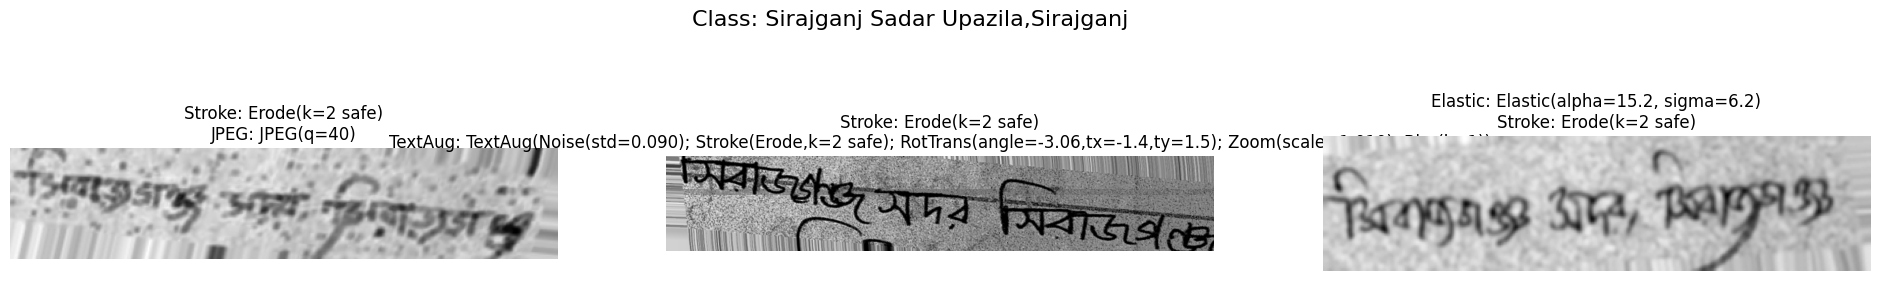

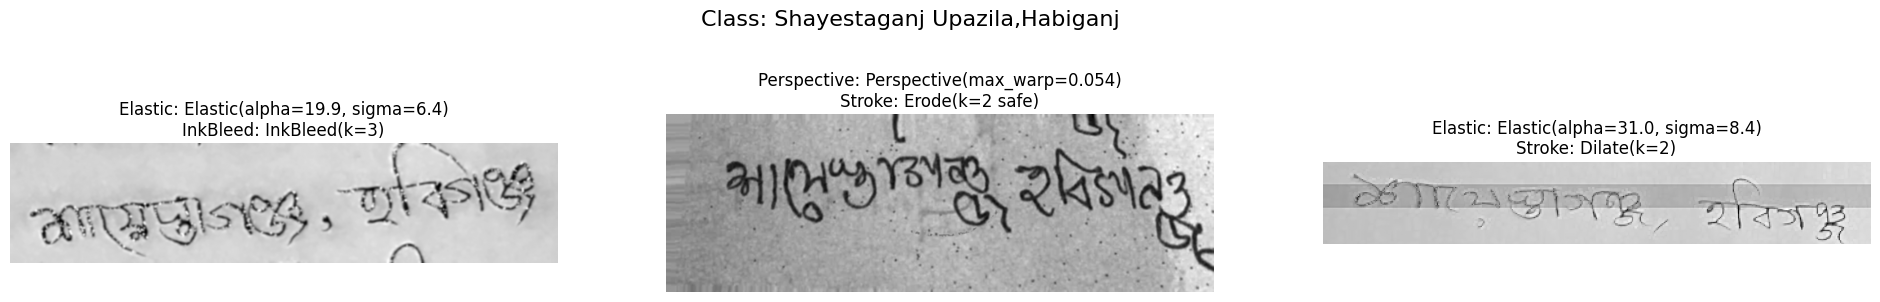

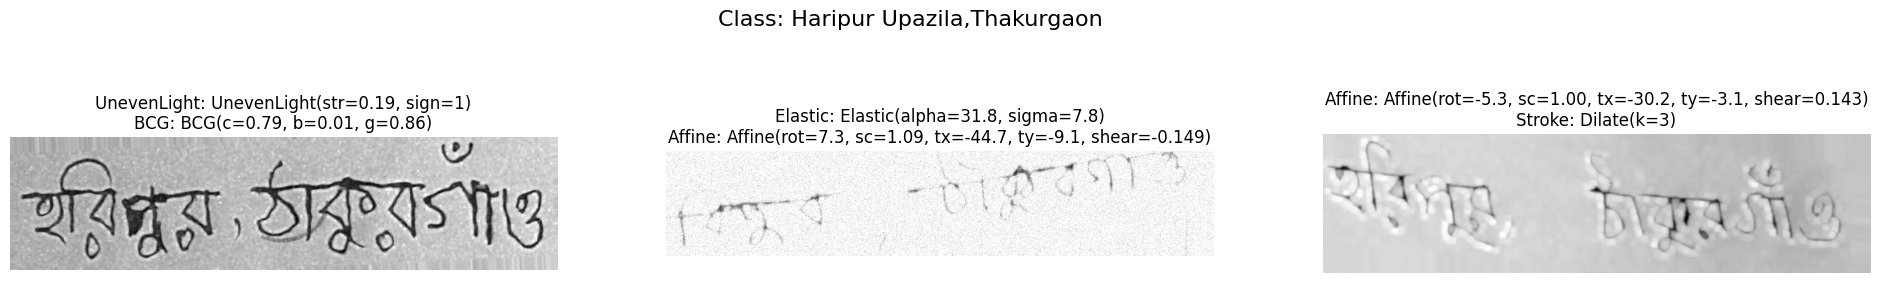

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path
import cv2
# ==============================
# PREVIEW AUGMENTATION IMAGES
# ==============================
def preview_augmentations(train_dir, n_classes=3, n_samples=3):
    """
    Randomly pick `n_classes` classes, then show `n_samples` augmented images per class.
    """
    class_dirs = sorted([p for p in Path(train_dir).iterdir() if p.is_dir()])
    selected_dirs = random.sample(class_dirs, min(n_classes, len(class_dirs)))

    for cd in selected_dirs:
        label = cd.name
        files = list_images(cd)
        if len(files) == 0:
            print(f"⚠️ No images in class {label}")
            continue

        # pick n_samples random source images
        sources = random.sample(files, min(n_samples, len(files)))
        plt.figure(figsize=(8*n_samples, 4))
        plt.suptitle(f"Class: {label}", fontsize=16)

        for i, src in enumerate(sources):
            img01 = read_gray01(src)
            if img01 is None:
                continue
            aug_u8, used_ops = augment_combo(img01)

            plt.subplot(1, n_samples, i+1)
            plt.imshow(aug_u8, cmap="gray")
            plt.title("\n".join(used_ops[:2]))  # show first 2 ops
            plt.axis("off")
        plt.show()

# ==============================
# CALL PREVIEW
# ==============================
preview_augmentations(train_dir, n_classes=3, n_samples=3)
